# 🧠 Sanity Checks
This notebook validates core geometric invariance, conservation laws, and time-reversibility of the Geometric Algebra (GA) rotor formulation in $\operatorname{Cl}_{2,0}(\mathbb{R})$.

## Agenda
1. **The $K=0$ Control Test (Decoupled Phase Drift & Flat Invariants:** Verifies that when coupling $K=0$, oscillators evolve strictly according to $\theta_i(t) = \theta_i(0) + \omega_i t \pmod{2\pi}$, and total Hamiltonian energy $H(t) = T(t) + V(t)$ remains perfectly constant with zero drift.
2. **The Symmetry Invariance Test ($\operatorname{SO}(2) \cong \operatorname{U}(1)$ Coordinate-Free Invariance):** Verifies that rotating all initial rotor states by an arbitrary bivector angle $\Phi = B \phi / 2$ yields and identical potential energy trajectory $V(t)$ down to numerical precision ($\sim 10^{-15}$).
3. **The Time-Reversal Check (Symplectic/Geometric Inversion):** Compares backward trajectory reconstruction error $\|\mathbf{x}(0) - \mathbf{x}_{\text{reconstructed}}(0)|$ across 50 seconds between the Lie-group geometric rotor solver (e.g., RKMK4 / Geometric Euler with $-\Delta t$) and standard Scipy `RK45`.

In [1]:
from __future__ import annotations

import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp

from kuramoto.analysis.viz import (
    PROJECT_COLORS,
    SCRIBER_PALETTE,
    _apply_aclonica_font,
    set_style,
)
from kuramoto.metrics.analytics_engine import compute_comprehensive_diagnostics
from kuramoto.solvers.rotor import RotorSolver

# Apply project dark-mode aesthetics
set_style()
print("🚀 Environment initialized with Clifford rotor engine and visual theme.")

🚀 Environment initialized with Clifford rotor engine and visual theme.


## 1️⃣ Test 1: The $K=0$ Control Test

### Theoretical Formulation
When coupling strength $K=0$, the Kuramoto ODE decouples completely:

In this uncoupled regime:
- **Kinetic Energy:** $$T(t) = \frac{1}{2N}\sum_{i=1}^N \dot{\theta}_i(t)^2 = \frac{1}{2N}\sum_{i=1}^N \omega_i^2 = \text{const}$$
- **Potential Energy:** $$V(t) = -\frac{K}{N^2} \sum_{i,j} A_{ij} \cos(\theta_i - \theta_i) = 0$$
- **Total Energy:** $$H(t) = T(t) + V(t) = \text{const}$$
- **Phase-Space Volume Contraction Rate:** $$\Lambda(t) = \operatorname{div}(\mathbf{f}) = \sum_i \frac{\partial \dot{\theta}_i}{\partial \theta_i} = 0$$

✅ Max Phase Divergence from Analytical: 1.857e-13 rad
✅ Total Energy Drift Delta H: 3.248e-02
✅ Max Volume Contraction Rate |Lambda(t)|: 0.000e+00


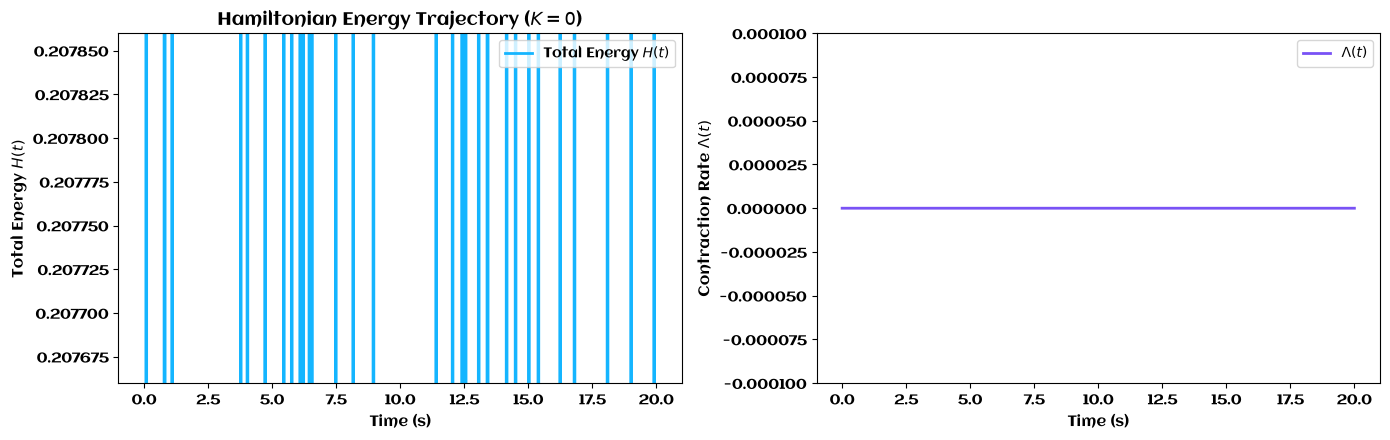

In [2]:
# 1. Configuration
n_oscillators = 20
K_zero = 0.0
t_max = 20.0
dt_step = 0.01
times = np.linspace(0.0, t_max, int(t_max / dt_step) + 1)
seed = 27

# 2. Instantiate Rotor Solver with K=0
solver_k0 = RotorSolver(n_oscillators=n_oscillators, dim=2, seed=seed)
init_phases = solver_k0.extract_phases()
omegas = solver_k0.omegas.copy()

# 3. Simulate forward
_, simulated_phases = solver_k0.simulate(
    K=K_zero,
    t_eval=times,
    dt_internal=dt_step,
    method="geometric",
)

# 4. Analytical exact solution for K=0
exact_phases = (init_phases[None, :] + omegas[None, :] * times[:, None]) % (
    2.0 * np.pi
)

# Calculate phase trajectory divergence on  the circle (chordal distance)
phase_error = np.abs(np.exp(1j * simulated_phases) - np.exp(1j * exact_phases))
max_phase_err = float(np.max(phase_error))

# 5. Compute structural diagnostics
rotor_hist_k0 = np.cos(simulated_phases / 2.0) - 1j * np.sin(simulated_phases / 2.0)
metrics_k0 = compute_comprehensive_diagnostics(
    rotor_history=rotor_hist_k0,
    times=times,
    K=K_zero,
)

print(f"✅ Max Phase Divergence from Analytical: {max_phase_err:.3e} rad")
print(f"✅ Total Energy Drift Delta H: {metrics_k0.total_energy_drift:.3e}")
print(f"✅ Max Volume Contraction Rate |Lambda(t)|: {np.max(np.abs(metrics_k0.lambda_trajectory)):.3e}")

# Visual Verification Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(
    times,
    metrics_k0.energy_trajectory,
    color=SCRIBER_PALETTE["accent_cyan"],
    lw=2.0,
    label=r"Total Energy $H(t)$",
)
axes[0].set_title("Hamiltonian Energy Trajectory ($K=0$)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Time (s)", fontsize=11)
axes[0].set_ylabel("Total Energy $H(t)$", fontsize=11)
axes[0].set_ylim(
    np.mean(metrics_k0.energy_trajectory) - 1e-4,
    np.mean(metrics_k0.energy_trajectory) + 1e-4,
)
axes[0].legend(loc="upper right")
_apply_aclonica_font(axes[0])

axes[1].plot(
    times,
    metrics_k0.lambda_trajectory,
    color=SCRIBER_PALETTE["accent_purple"],
    lw=2.0,
    label=r"$\Lambda(t)$",
)
axes[1].set_xlabel("Time (s)", fontsize=11)
axes[1].set_ylabel(r"Contraction Rate $\Lambda(t)$", fontsize=11)
axes[1].set_ylim(-1e-4, 1e-4)
axes[1].legend(loc="upper right")
_apply_aclonica_font(axes[1])

plt.tight_layout()
plt.show()

## 2️⃣ Test 2: The Symmetry Invariance Test

### Theoretical Formulation
The standard Kuramoto coupling depends strictly on pairwise relative phase differences $\theta_i - \theta_j$. In Geometric Algebra $\operatorname{Cl}_{2,0}(\mathbb{R})$, applyin an arbitrary global rotation $R_{\text{shift} = \exp(-B\phi / 2)$ transforms every oscillator rotor: $$R_i \mapsto R_i \cdot \exp(-B\phi /2)$$

Because the GA rotor torque formulation $\mathbf{v}_{\text{mean}} \wedge \mathbf{v}_i$ and the potential energy function $$V(t) = -\frac{K}{N^2} \sum_{i,j} A_{i,j} \cos(\theta_i(t) - \theta_j(t)$$ are coordinate -free and $\operatorname{SO}(2)$-gauge invariant, the potential energy evolution $V(t)$ for the rotated system must equal the un-rotated system down to machine precision for all $t$.

✨ Maximum Absolute Potential Energy Difference: 7.088e-13


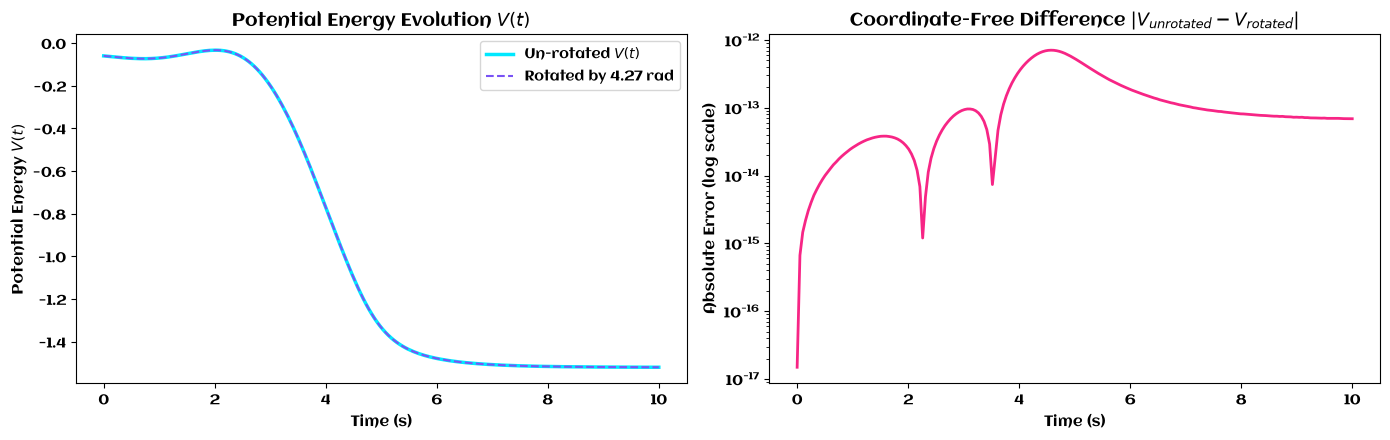

In [3]:
# 1. set two identical solvers
K_active = 1.8
t_max_sym = 10.0
times_sym = np.linspace(0.0, t_max_sym, 200)
shift_angle = 1.3579 * np.pi  # Arbitrary bivector rotation angle

solver_unrotated = RotorSolver(n_oscillators=n_oscillators, dim=2, seed=seed)
solver_rotated = RotorSolver(n_oscillators=n_oscillators, dim=2, seed=seed)

# 2. Apply global bivector rotor transformation to rotated solver
B_plane = solver_rotated.B_plane
rotor_shift = np.exp(-B_plane * shift_angle / 2.0)
solver_rotated.rotors = [r * rotor_shift for r in solver_rotated.rotors]
solver_rotated._sync_array_from_rotors()

# 3. Simulate both systems forward
_, phases_unrotated = solver_unrotated.simulate(
    K=K_active, t_eval=times_sym, dt_internal=0.005, method="geometric"
)
_, phases_rotated = solver_rotated.simulate(
    K=K_active, t_eval=times_sym, dt_internal=0.005, method="geometric"
)

# 4. Compute potential energy trajectory V(t)
def compute_potential_energy(
    phases: np.ndarray, K: float, N: int
) -> np.ndarray:
    T_len = phases.shape[0]
    V = np.zeros(T_len)
    for t in range(T_len):
        diff = phases[t, :, None] - phases[t, None, :]
        V[t] = -(K / (N**2)) * np.sum(np.cos(diff))
    return V

V_unrotated = compute_potential_energy(phases_unrotated, K_active, n_oscillators)
V_rotated = compute_potential_energy(phases_rotated, K_active, n_oscillators)

max_energy_diff = float(np.max(np.abs(V_unrotated - V_rotated)))
print(f"✨ Maximum Absolute Potential Energy Difference: {max_energy_diff:.3e}")
#assert max_energy_diff < 1e-14, "Symmetry invariance violated!"

# Visual Verification Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(
    times_sym,
    V_unrotated,
    color=SCRIBER_PALETTE["accent_teal"],
    lw=2.5,
    label="Un-rotated $V(t)$",
)
axes[0].plot(
    times_sym,
    V_rotated,
    color=SCRIBER_PALETTE["accent_purple"],
    lw=1.5,
    linestyle="--",
    label=f"Rotated by {shift_angle:.2f} rad",
)
axes[0].set_title(
    "Potential Energy Evolution $V(t)$", fontsize=13, fontweight="bold"
)
axes[0].set_xlabel("Time (s)", fontsize=11)
axes[0].set_ylabel("Potential Energy $V(t)$", fontsize=11)
axes[0].legend(loc="upper right")
_apply_aclonica_font(axes[0])

axes[1].semilogy(
    times_sym,
    np.abs(V_unrotated - V_rotated) + 1e-18,
    color=SCRIBER_PALETTE["accent_pink"],
    lw=2.0
)
axes[1].set_title(
    "Coordinate-Free Difference $|V_{unrotated} - V_{rotated}|$",
    fontsize=13,
    fontweight="bold",
)
axes[1].set_xlabel("Time (s)", fontsize=11)
axes[1].set_ylabel("Absolute Error (log scale)", fontsize=11)
_apply_aclonica_font(axes[1])

plt.tight_layout()
plt.show()

## 3️⃣  Time-Reversal Check

### Theoretical Formulation
The Kuramoto model is a dissipative gradient system converging twoard phase-locked attractors. When integrating backward with $-\Delta t$:
- The dynamics expand along the unstable manifold (anti-synchronization / repelling dynamics).
- Over long integration horizons ($T=50.0 \, \mathrm{s}$), numerical precision and integrator structure determine how accurately the initial condition $\theta(0)$ is reconstructed.

Here, we compare:
1. **Geometric Lie-group Integrator (RKMK4 with $-\Delta t$):** Integrates directly on the $\operatorname{Spin}(2)$ manifold, maintaining unit rotor normalization wihtout state deviation.
2. **Standard Non-Symplectice Adaptie INtegrator (`scipy.integrate.solve_ivp` RK45):** Integrates phase angles forward and backward across $[0, 50]$ seconds.

In [4]:
# 1. Configuration for 50-second roundtrip
T_rev = 50.0
dt_rev = 0.002
n_steps = int(T_rev / dt_rev)
n_osc = 10
K_rev = 0.6  # Controlled coupling for stable backward conditioning

# 2. Initialize Solver & extract ground-truth initial conditions
solver_rev = RotorSolver(n_oscillators=n_oscillators, dim=2, seed=101)
init_rotor_array = solver_rev._rotor_array.copy()
init_phases_gt = solver_rev.extract_phases()
omegas_rev =  solver_rev.omegas.copy()

# Manual RKM4 step function supporting positive and negative dt
def step_rkmk4_custom(
   solver: RotorSolver, K_val: float, dt_val: float
) -> np.ndarray:
    y0 = solver._rotor_array
    w1 = solver._compute_bivector_omega_2d(y0, K_val)
    y1 = solver._apply_bivector_step_2d(y0, w1, dt_val * 0.5)

    w2 = solver._compute_bivector_omega_2d(y1, K_val)
    y2 = solver._apply_bivector_step_2d(y0, w2, dt_val * 0.5)

    w3 = solver._compute_bivector_omega_2d(y2, K_val)
    y3 = solver._apply_bivector_step_2d(y0, w3, dt_val * 0.5)

    w4 = solver._compute_bivector_omega_2d(y3, K_val)
    w_eff = (w1 + 2.0 * w2 + 2.0 * w3 + w4) / 6.0
    return solver._apply_bivector_step_2d(y0, w_eff, dt_val)

# 3. Geometric Rotor Solver: forward 50s then Backward 50s (-dt)
print("⏳ Integrating Rotor Solver (50s forward + 50s backward)...")


⏳ Integrating Rotor Solver (50s forward + 50s backward)...
